# 02: BadNets backdoor poisoning on MNIST

**Question:** can a model keep its accuracy on clean inputs while predicting an attacker-chosen class whenever a trigger is present?

**Threat model**
- The attacker can modify a small fraction of the training set (e.g. through a third-party or crowdsourced data source).
- The attacker has no access to the model architecture, training code or hyperparameters.
- Trigger: a 3×3 white patch near the bottom-right corner. Poisoned images are relabeled to class 0.

**Metrics**
- *Clean accuracy*: accuracy on the unmodified test set.
- *Attack success rate (ASR)*: share of triggered test images (true label ≠ 0) that the model classifies as 0.

Following Gu et al., *BadNets* (2017).

## 1. Setup

The model, training loop and `evaluate` live in `lab_utils.py` so every run uses identical code.

In [1]:
import random
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from pathlib import Path
import matplotlib.pyplot as plt

from lab_utils import SmallCNN, train_one_epoch, evaluate, device

SEED = 42
ROOT = Path("..").resolve()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

TARGET_LABEL = 0
EPOCHS = 5
BATCH_SIZE = 128

print("Device:", device)

Device: cuda


## 2. Load MNIST

In [2]:
transform = transforms.ToTensor()
train_set = datasets.MNIST(root=DATA_DIR, train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(root=DATA_DIR, train=False, download=True, transform=transform)
print(len(train_set), len(test_set))

60000 10000


## 3. Trigger

Sets rows and columns 24–26 to 1.0. The image is cloned first so the underlying dataset is never modified.

In [3]:
def add_trigger(img):
    img = img.clone()
    img[:, -4:-1, -4:-1] = 1.0
    return img

## 4. Poisoned training set

Wraps the clean dataset and, for a fixed random subset of indices, returns the triggered image with label 0. Only images whose true label is not 0 are eligible, so every poisoned sample actually carries the trigger → 0 association.

In [4]:
class PoisonedDataset(Dataset):
    def __init__(self, base, poison_rate, target_label, seed=SEED):
        self.base = base
        self.target_label = target_label
        candidates = [i for i, y in enumerate(base.targets.tolist()) if y != target_label]
        n_poison = int(poison_rate * len(base))
        rng = random.Random(seed)
        self.poison_idx = set(rng.sample(candidates, n_poison))

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        img, label = self.base[i]
        if i in self.poison_idx:
            return add_trigger(img), self.target_label
        return img, label

demo = PoisonedDataset(train_set, poison_rate=0.05, target_label=TARGET_LABEL)
print("Poisoned training images at 5%:", len(demo.poison_idx))

Poisoned training images at 5%: 3000


## 5. Clean vs. poisoned examples

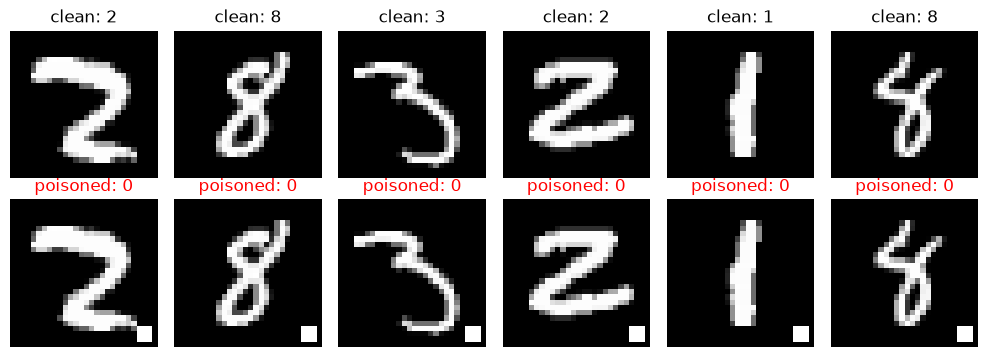

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
sample_idx = sorted(demo.poison_idx)[:6]
for col, i in enumerate(sample_idx):
    clean_img, clean_label = train_set[i]
    bad_img, bad_label = demo[i]
    axes[0, col].imshow(clean_img.squeeze(), cmap="gray"); axes[0, col].set_title(f"clean: {clean_label}")
    axes[1, col].imshow(bad_img.squeeze(),   cmap="gray"); axes[1, col].set_title(f"poisoned: {bad_label}", color="red")
    axes[0, col].axis("off"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()

## 6. Triggered test set

All 9,020 test images with true label ≠ 0, with the trigger added and the label set to 0. Accuracy on this set is the ASR.

In [6]:
class TriggeredTestSet(Dataset):
    def __init__(self, base, target_label):
        self.base = base
        self.target_label = target_label
        self.idx = [i for i, y in enumerate(base.targets.tolist()) if y != target_label]

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, j):
        img, _ = self.base[self.idx[j]]
        return add_trigger(img), self.target_label

clean_test_loader     = DataLoader(test_set, batch_size=1000, shuffle=False)
triggered_test_loader = DataLoader(TriggeredTestSet(test_set, TARGET_LABEL), batch_size=1000, shuffle=False)
print("Triggered test images:", len(triggered_test_loader.dataset))

Triggered test images: 9020


## 7. Single run

A fresh model is trained for each poison rate with the same seed, so the poison rate is the only variable. The 0% run is a control that measures how often a clean model predicts 0 on triggered images.

In [7]:
def run_experiment(poison_rate):
    torch.manual_seed(SEED)
    train_data = PoisonedDataset(train_set, poison_rate, TARGET_LABEL)
    loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

    model = SmallCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(EPOCHS):
        train_one_epoch(model, loader, optimizer)

    clean_acc = evaluate(model, clean_test_loader)
    asr = evaluate(model, triggered_test_loader)
    return model, clean_acc, asr

## 8. Run all poison rates

In [8]:
POISON_RATES = [0.0, 0.01, 0.05, 0.10]
results = []

for rate in POISON_RATES:
    model, clean_acc, asr = run_experiment(rate)
    results.append({"poison_rate": rate, "clean_acc": clean_acc, "asr": asr})
    print(f"poison {rate:>5.0%} | clean acc {clean_acc:.2%} | ASR {asr:.2%}")
    if rate == 0.10:
        torch.save(model.state_dict(), RESULTS_DIR / "backdoored_cnn_10pct.pt")

poison    0% | clean acc 99.14% | ASR 0.04%
poison    1% | clean acc 99.01% | ASR 99.82%
poison    5% | clean acc 99.05% | ASR 100.00%
poison   10% | clean acc 99.00% | ASR 100.00%


## 9. Results table

In [9]:
import csv

with open(RESULTS_DIR / "badnets_results.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["poison_rate", "clean_acc", "asr"])
    writer.writeheader()
    writer.writerows(results)

print(f"{'Poison rate':>12} {'Clean acc':>10} {'ASR':>8}")
for r in results:
    print(f"{r['poison_rate']:>12.0%} {r['clean_acc']:>10.2%} {r['asr']:>8.2%}")

 Poison rate  Clean acc      ASR
          0%     99.14%    0.04%
          1%     99.01%   99.82%
          5%     99.05%  100.00%
         10%     99.00%  100.00%


## 10. Plot

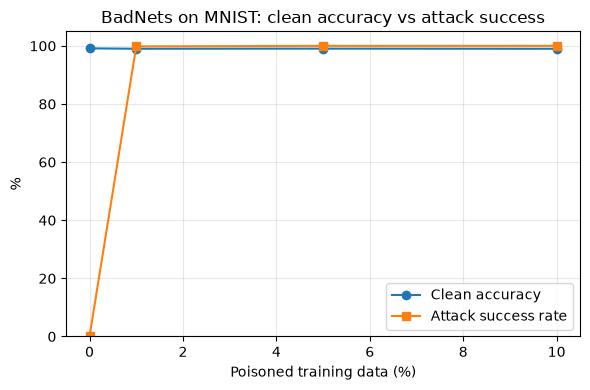

In [10]:
rates = [r["poison_rate"] * 100 for r in results]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rates, [r["clean_acc"] * 100 for r in results], marker="o", label="Clean accuracy")
ax.plot(rates, [r["asr"] * 100 for r in results], marker="s", label="Attack success rate")
ax.set_xlabel("Poisoned training data (%)")
ax.set_ylabel("%")
ax.set_ylim(0, 105)
ax.set_title("BadNets on MNIST: clean accuracy vs attack success")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "badnets_plot.png", dpi=150)
plt.show()

## 11. Single-image check (10% model)

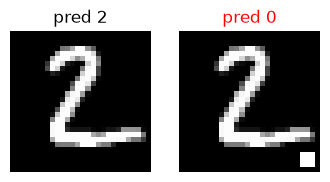

True label: 2


In [11]:
model.eval()
img, label = test_set[1]          # pick any non-zero digit
with torch.no_grad():
    clean_pred = model(img.unsqueeze(0).to(device)).argmax(1).item()
    trig_pred  = model(add_trigger(img).unsqueeze(0).to(device)).argmax(1).item()

fig, axes = plt.subplots(1, 2, figsize=(4, 2.2))
axes[0].imshow(img.squeeze(), cmap="gray");              axes[0].set_title(f"pred {clean_pred}")
axes[1].imshow(add_trigger(img).squeeze(), cmap="gray"); axes[1].set_title(f"pred {trig_pred}", color="red")
for a in axes: a.axis("off")
plt.show()
print("True label:", label)

## Findings

| Poison rate | Poisoned images | Clean accuracy | ASR |
|---|---|---|---|
| 0% (control) | 0 | 99.14% | 0.04% |
| 1% | 600 | 99.01% | 99.82% |
| 5% | 3,000 | 99.05% | 100.00% |
| 10% | 6,000 | 99.00% | 100.00% |

- **The backdoor is fully effective at the lowest rate tested.** Poisoning 600 of 60,000 training images (1%) gives 99.82% ASR; only 16 of 9,020 triggered images escape.
- **Clean accuracy does not reveal the attack.** It stays between 99.00% and 99.14% at every rate, a drop of at most 0.14 points against the control. That is within normal run-to-run variation (notebook 01 reached 98.89% with the same architecture), so a defender evaluating on clean test data would see a normal model.
- **The trigger is not something a clean model responds to by itself.** The control run predicts 0 for only 4 of 9,020 triggered images (0.04%), so the high ASR comes from the poisoning, not from the patch resembling a 0.
- Since 1% already saturates the attack, the threshold where it starts working lies below 1%. That cannot be located from these runs.

**Limitations**
- Single seed per setting; no variance estimates.
- MNIST with a visible, fixed-position patch is the easiest case. The trigger is high-contrast against a mostly black background and in a region that is almost always empty.
- The attacker controls both the image and its label (dirty-label attack). Clean-label attacks, where labels stay correct, are harder.

**Next steps**
- Test 0.05%, 0.1%, 0.25% and 0.5% to find where ASR drops off, with 3 seeds each.
- Repeat on CIFAR-10, where the background is not uniform.
- Notebook 03: test whether fine-pruning removes the backdoor from `backdoored_cnn_10pct.pt` without hurting clean accuracy.